## Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="Set2")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

## Load cleaned dataset

In [2]:
df = pd.read_csv(
    "../data/processed/telco_customer_churn_cleaned.csv"
)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## Membuat kolom analisis tambahan

In [4]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-60 Months",
        "61-72 Months"
    ]
)

df[["tenure", "TenureGroup"]].head()

,tenure,TenureGroup
0,1,0-12 Months
1,34,25-48 Months
2,2,0-12 Months
3,45,25-48 Months
4,2,0-12 Months


## Distribusi gender

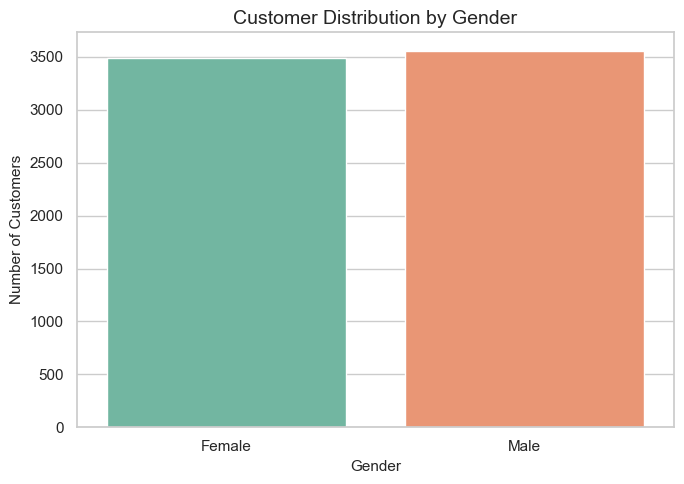

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="gender",
    hue="gender",
    legend=False
)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

## Distribusi status pelanggan

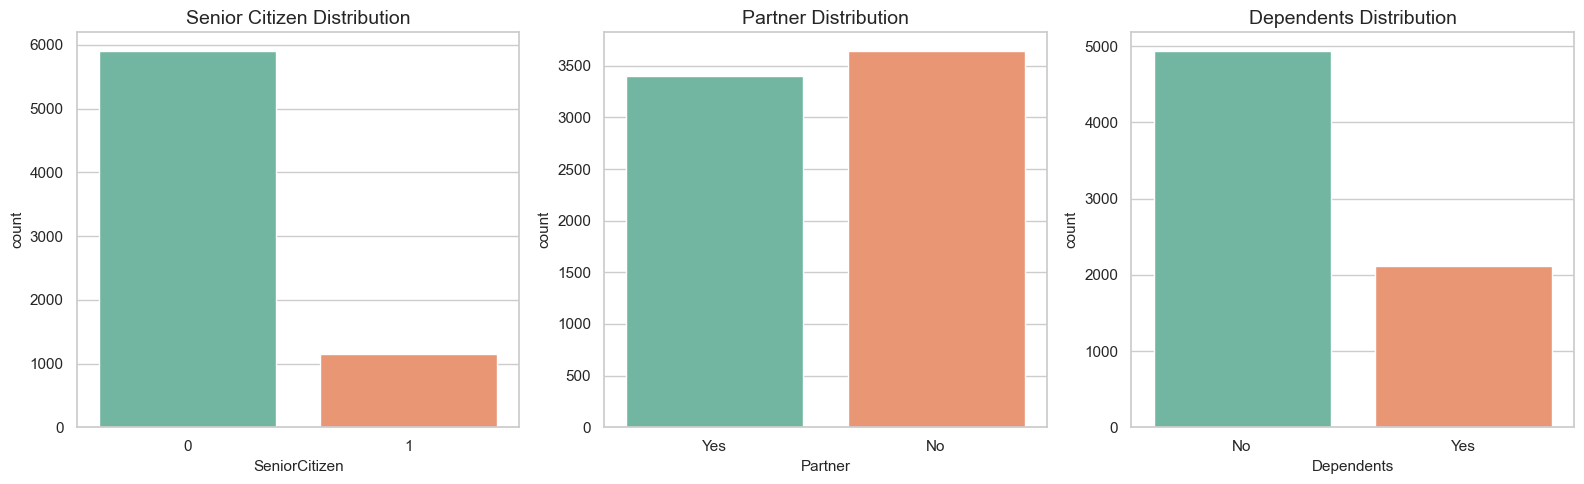

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.countplot(
    data=df, x="SeniorCitizen",
    hue="SeniorCitizen", legend=False,
    ax=axes[0]
)
axes[0].set_title("Senior Citizen Distribution")

sns.countplot(
    data=df, x="Partner",
    hue="Partner", legend=False,
    ax=axes[1]
)
axes[1].set_title("Partner Distribution")

sns.countplot(
    data=df, x="Dependents",
    hue="Dependents", legend=False,
    ax=axes[2]
)
axes[2].set_title("Dependents Distribution")

plt.tight_layout()
plt.show()

## Churn distribution

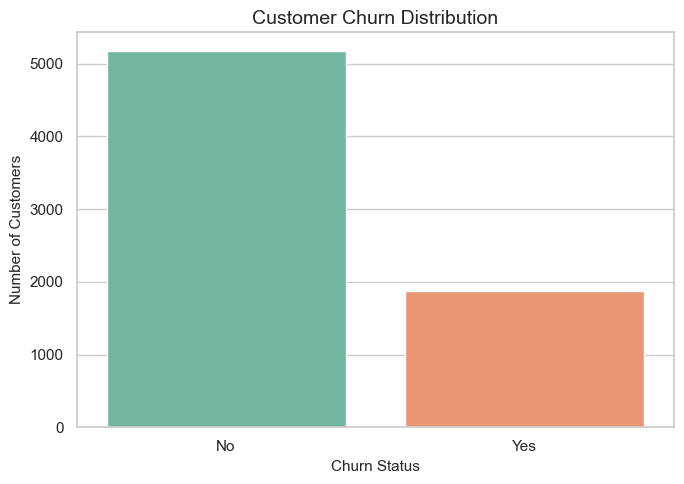

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

## Churn percentage

In [8]:
churn_rate = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(churn_rate)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


## Churn rate berdasarkan demographics

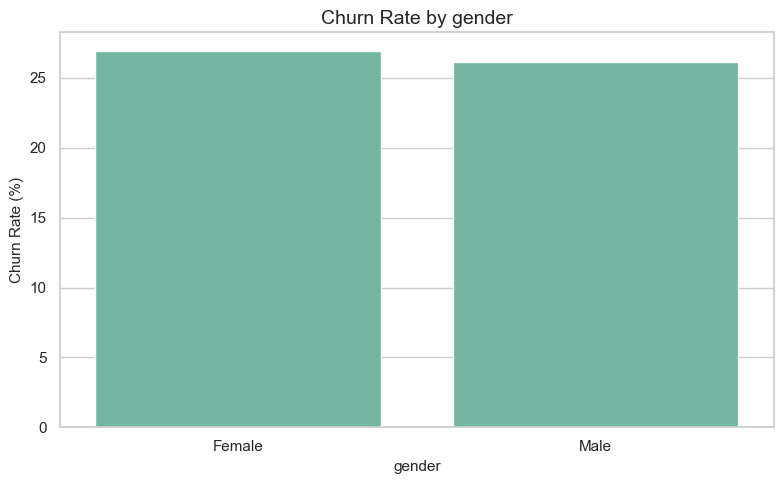

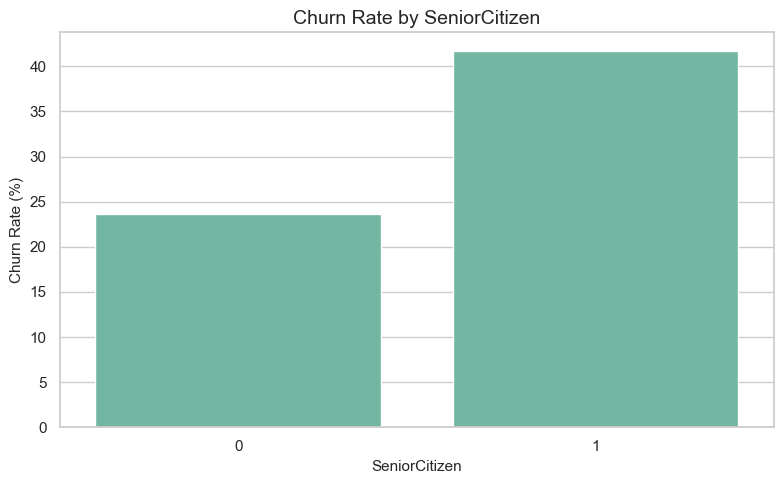

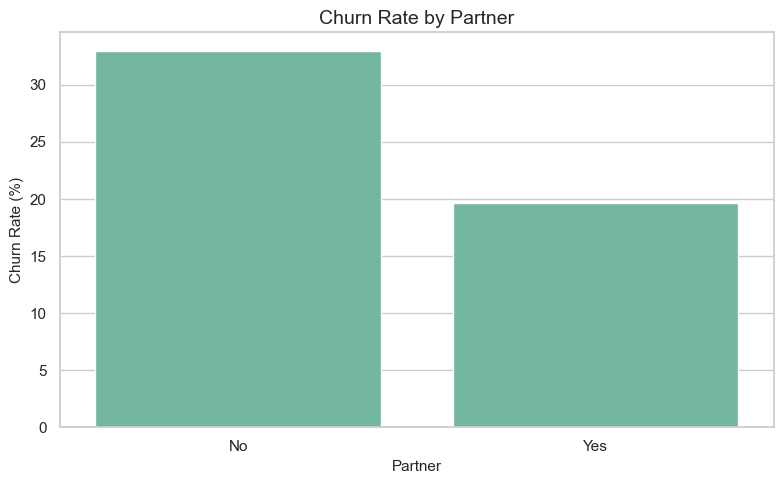

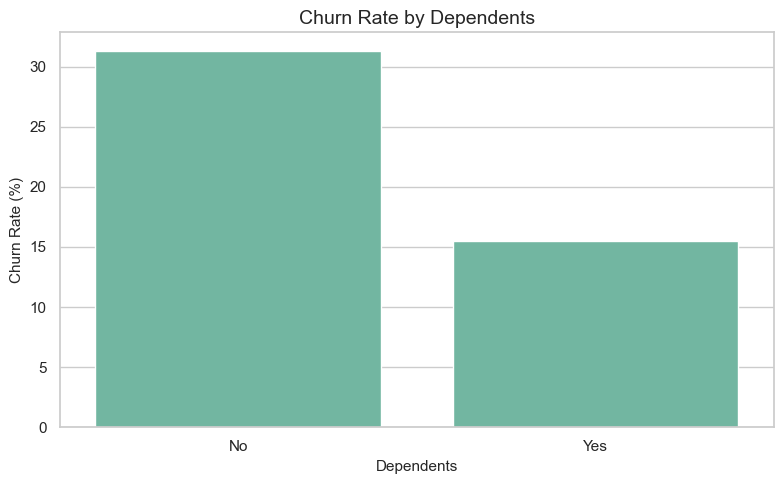

In [9]:
demographic_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

for column in demographic_columns:

    result = (
        df.groupby(column, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="ChurnRate")
    )

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=result,
        x=column,
        y="ChurnRate"
    )

    plt.title(f"Churn Rate by {column}")
    plt.ylabel("Churn Rate (%)")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

## Tenure distribution

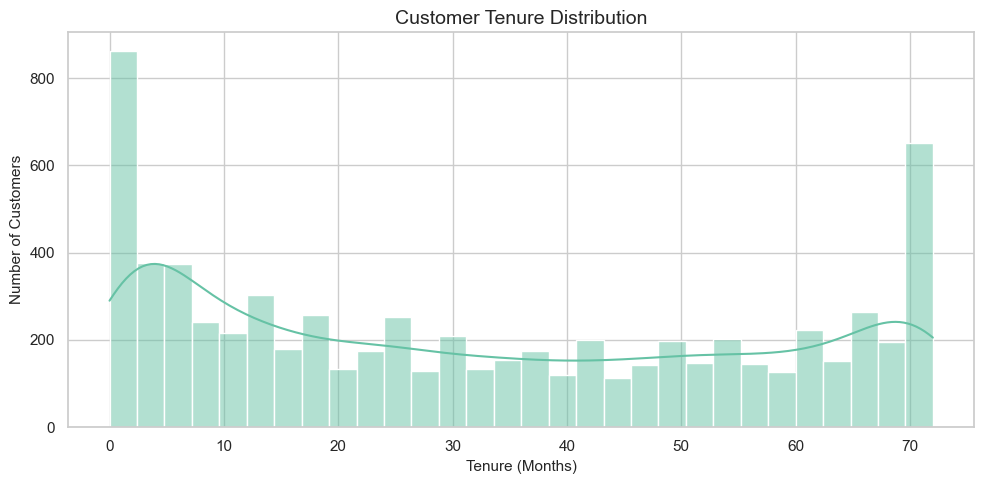

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    bins=30,
    kde=True
)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

## Churn berdasarkan tenure group

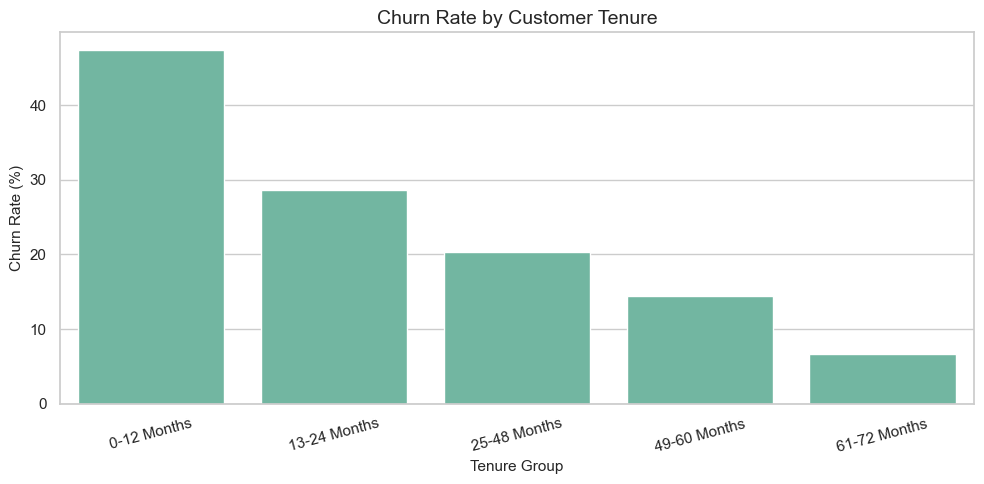

,TenureGroup,ChurnRate
0,0-12 Months,47.438243
1,13-24 Months,28.710938
2,25-48 Months,20.388959
3,49-60 Months,14.423077
4,61-72 Months,6.609808


In [11]:
tenure_churn = (
    df.groupby("TenureGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=tenure_churn,
    x="TenureGroup",
    y="ChurnRate"
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

tenure_churn

## Contract distribution

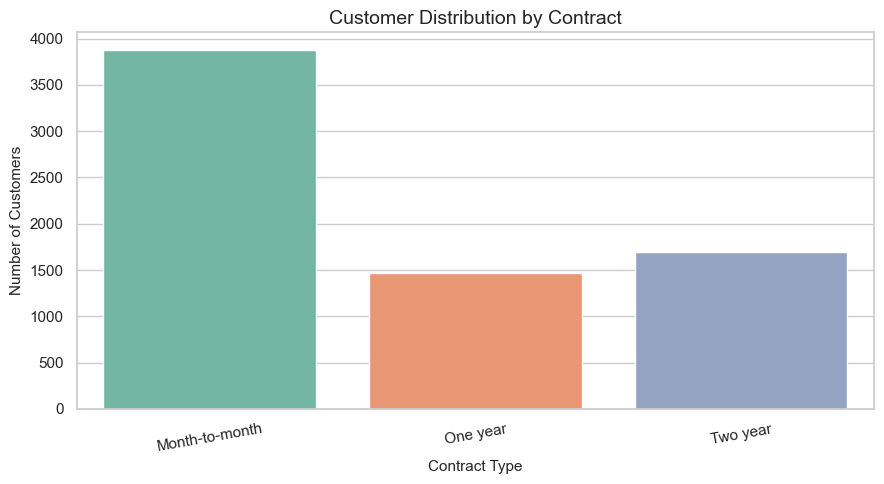

In [12]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Contract",
    legend=False
)

plt.title("Customer Distribution by Contract")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=10)

plt.tight_layout()
plt.show()

## Churn rate by contract

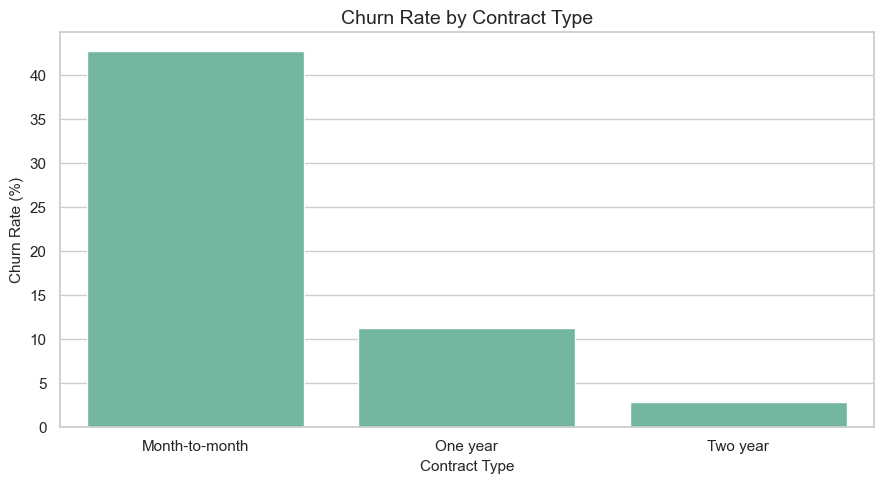

,Contract,ChurnRate
0,Month-to-month,42.709677
1,One year,11.269518
2,Two year,2.831858


In [15]:
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
    .sort_values("ChurnRate", ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=contract_churn,
    x="Contract",
    y="ChurnRate",
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

contract_churn

## Service churn analysis

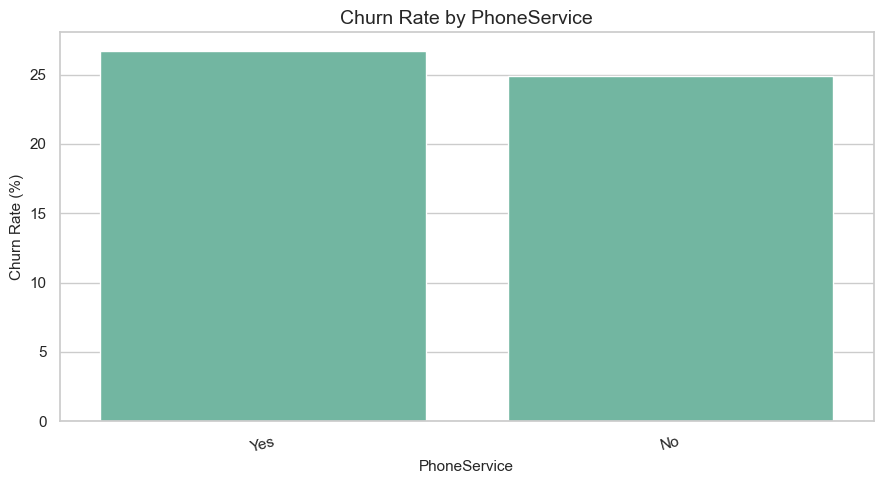

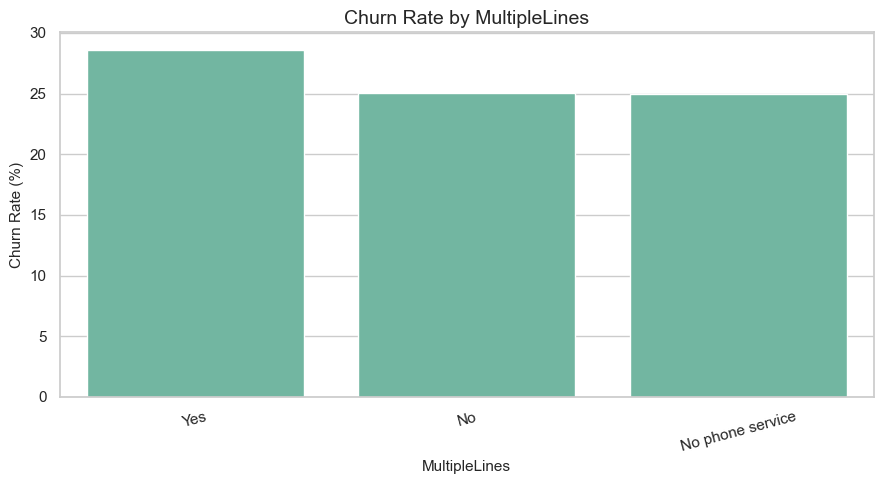

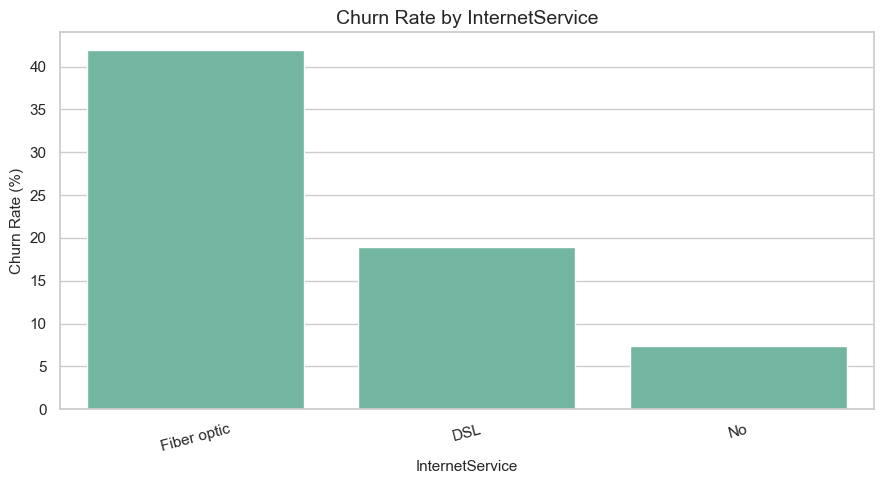

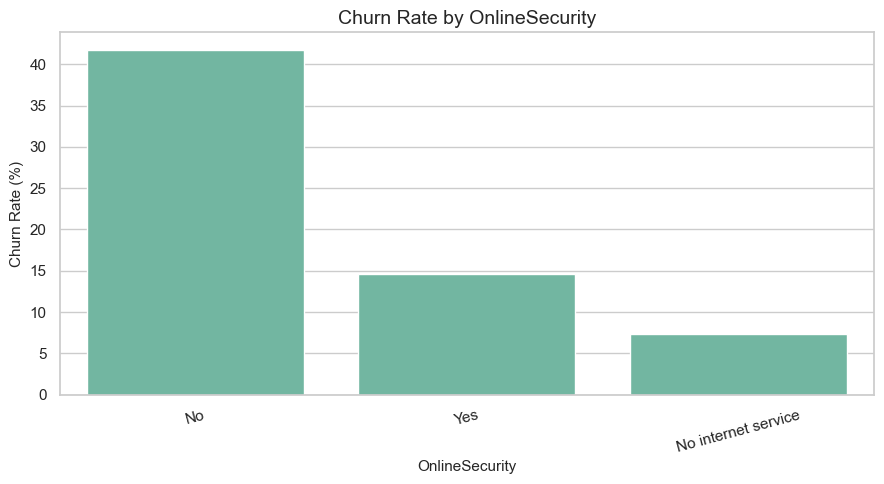

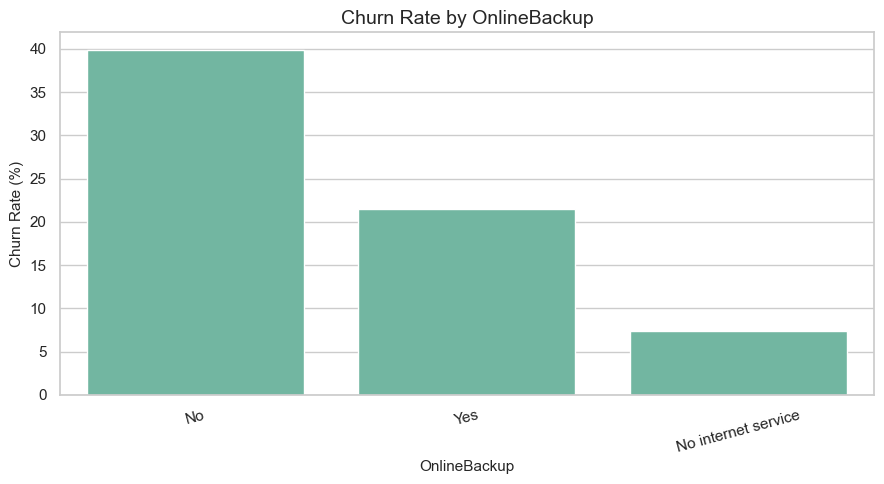

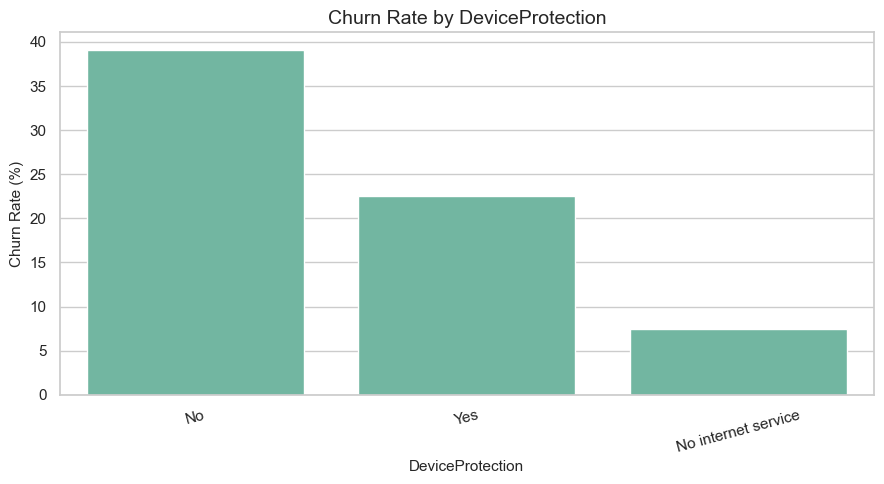

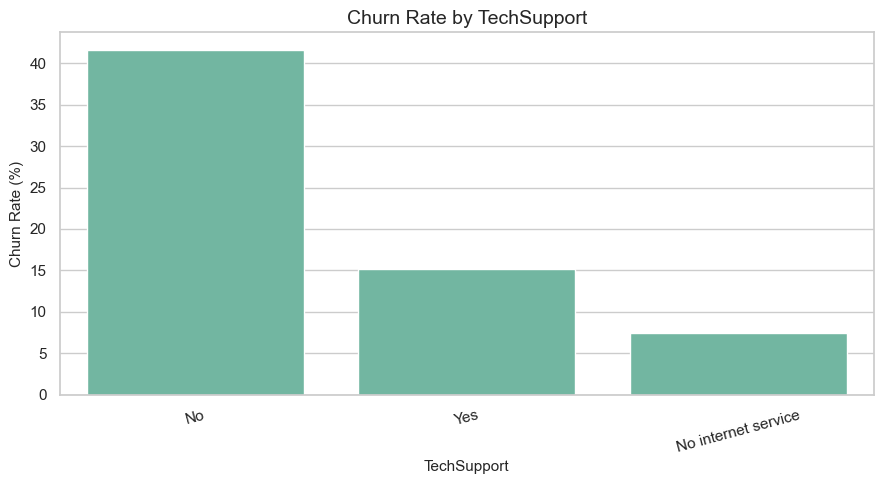

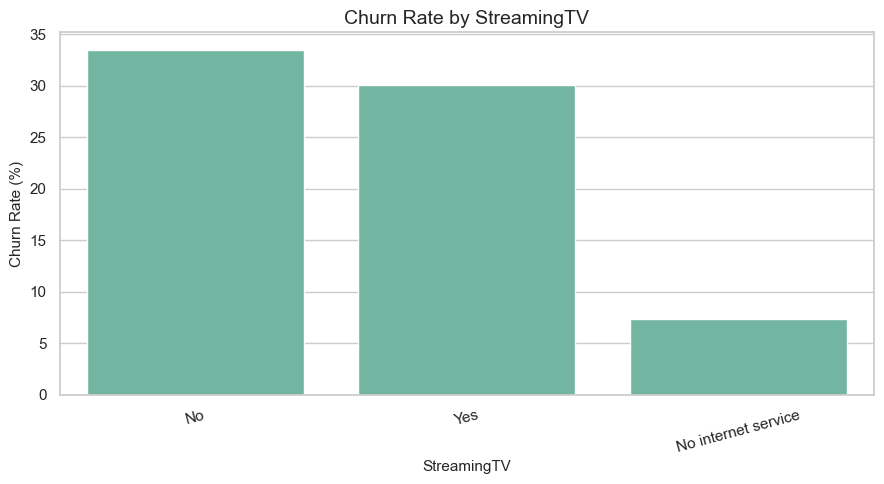

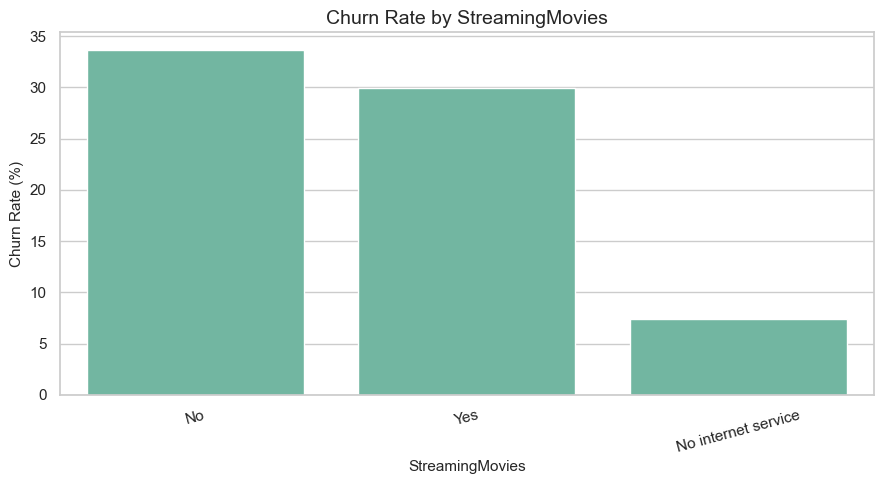

In [16]:
service_columns = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

for column in service_columns:

    result = (
        df.groupby(column)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="ChurnRate")
        .sort_values("ChurnRate", ascending=False)
    )

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=result,
        x=column,
        y="ChurnRate"
    )

    plt.title(f"Churn Rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=15)

    plt.tight_layout()
    plt.show()

## Payment method distribution

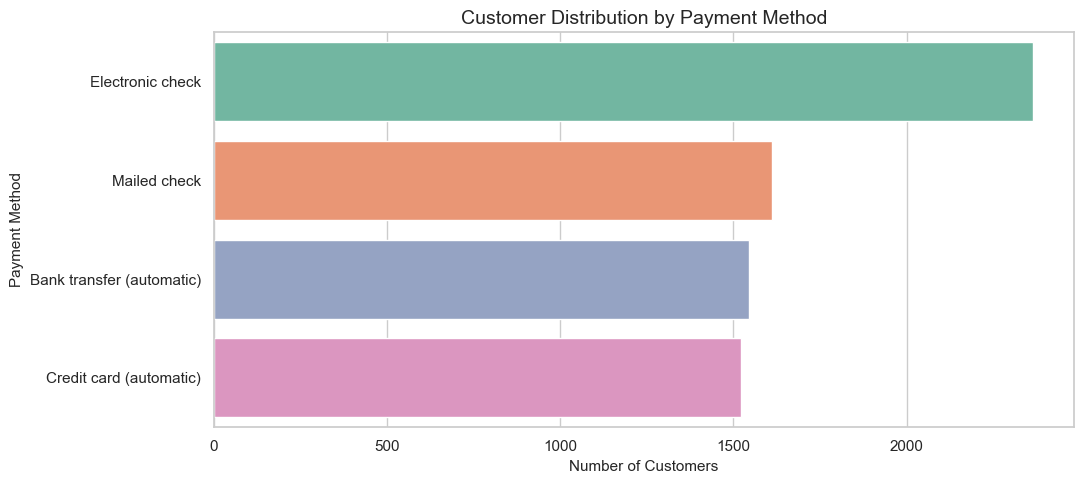

In [18]:
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    y="PaymentMethod",
    hue="PaymentMethod",
    legend=False,
    order=df["PaymentMethod"].value_counts().index
)

plt.title("Customer Distribution by Payment Method")
plt.xlabel("Number of Customers")
plt.ylabel("Payment Method")

plt.tight_layout()
plt.show()

## Churn rate by payment method

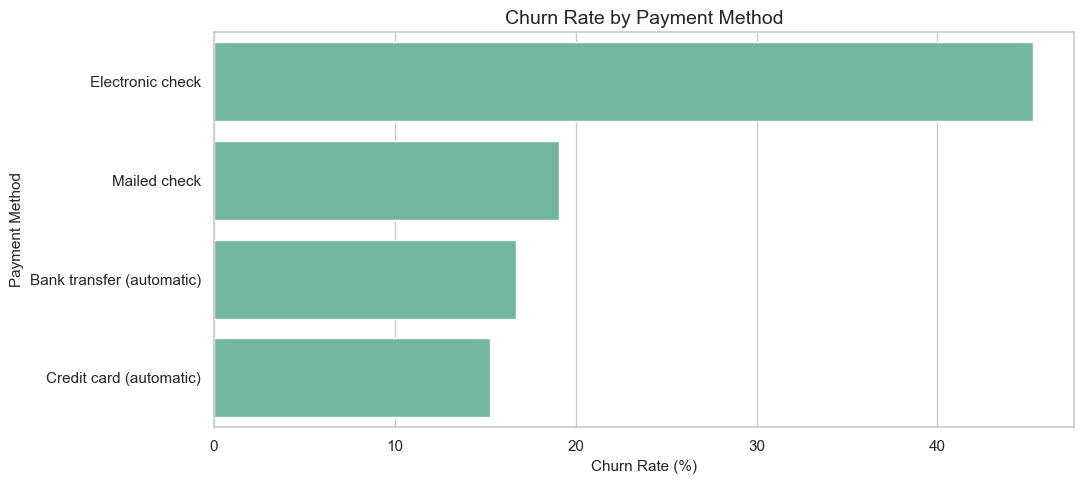

,PaymentMethod,ChurnRate
2,Electronic check,45.285412
3,Mailed check,19.106700
0,Bank transfer (automatic),16.709845
1,Credit card (automatic),15.243101


In [19]:
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
    .sort_values("ChurnRate", ascending=False)
)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=payment_churn,
    x="ChurnRate",
    y="PaymentMethod"
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Payment Method")

plt.tight_layout()
plt.show()

payment_churn

## Monthly charges distribution

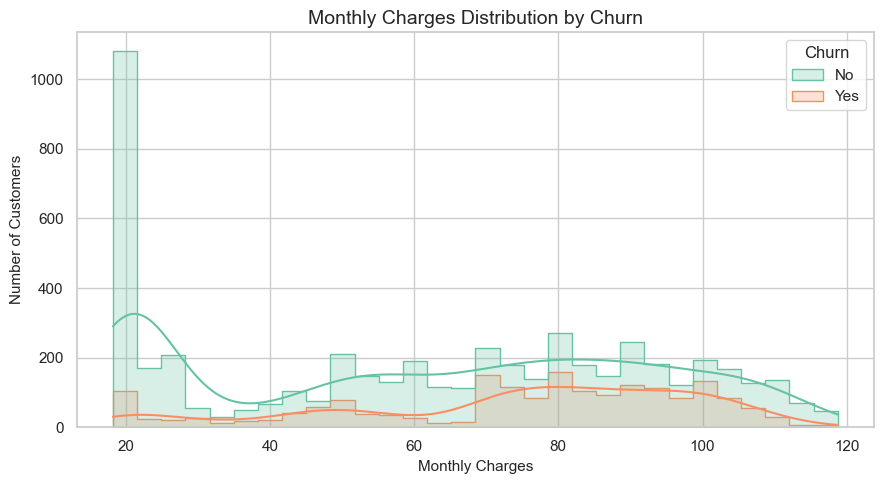

In [20]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    kde=True,
    bins=30,
    element="step"
)

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

## Monthly charges by churn

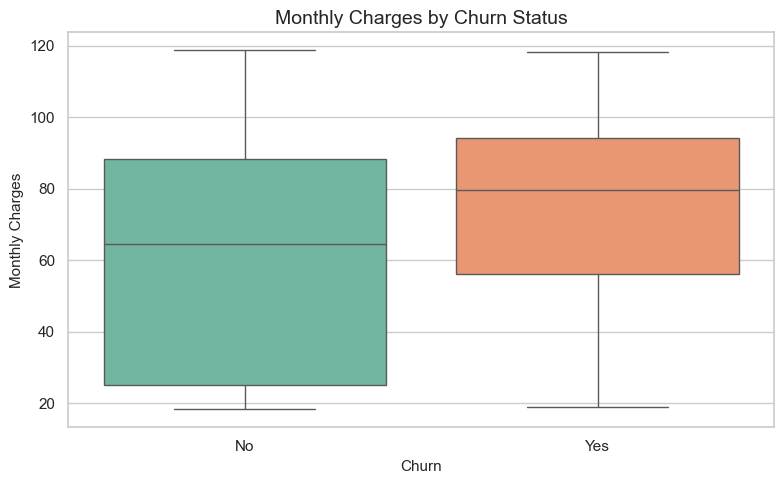

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    legend=False
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

## Total charges by churn

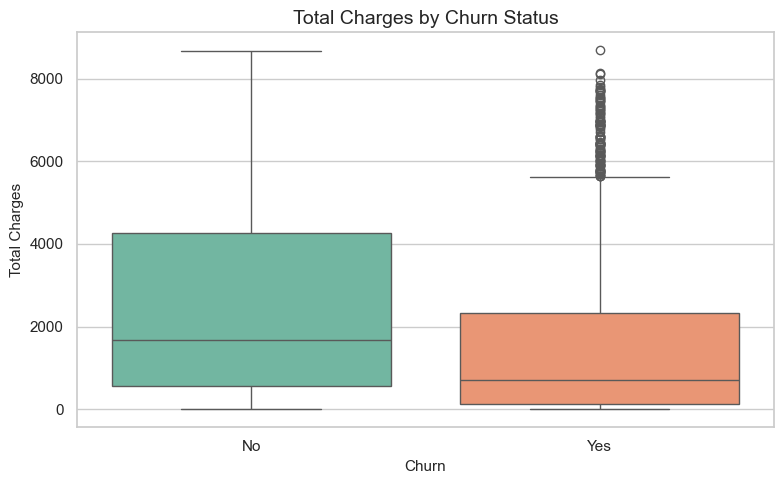

In [23]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges",
    hue="Churn",
    legend=False
)

plt.title("Total Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.tight_layout()
plt.show()

## Financial summary

In [24]:
financial_summary = (
    df.groupby("Churn")
    .agg(
        Total_Customers=("customerID", "count"),
        Avg_Monthly_Charges=("MonthlyCharges", "mean"),
        Median_Monthly_Charges=("MonthlyCharges", "median"),
        Avg_Total_Charges=("TotalCharges", "mean"),
        Median_Total_Charges=("TotalCharges", "median")
    )
    .round(2)
)

financial_summary

,Total_Customers,Avg_Monthly_Charges,Median_Monthly_Charges,Avg_Total_Charges,Median_Total_Charges
Churn,,,,,
No,5174,61.27,64.43,2549.91,1679.52
Yes,1869,74.44,79.65,1531.80,703.55


## Correlation matrix

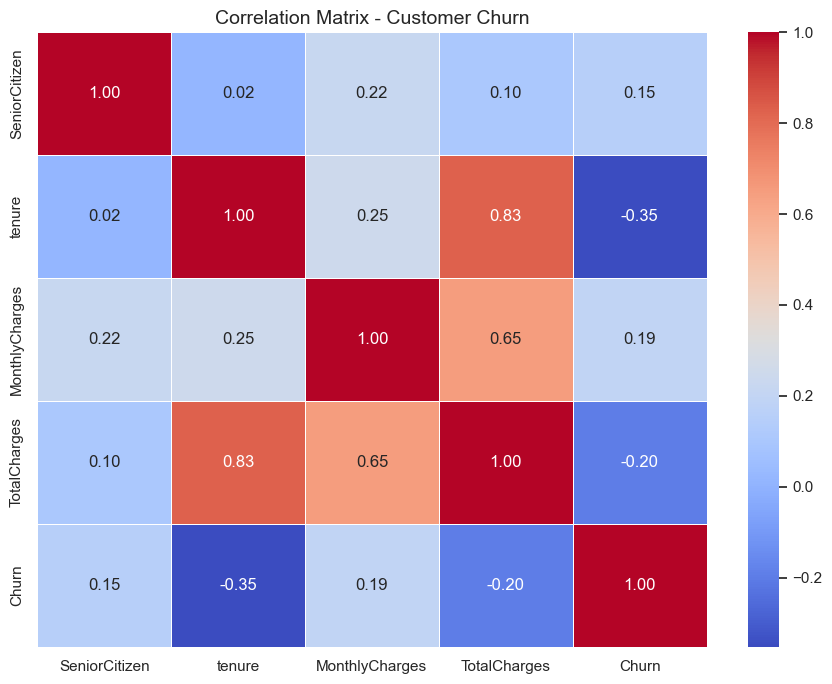

In [25]:
correlation_df = df[
    [
        "SeniorCitizen",
        "tenure",
        "MonthlyCharges",
        "TotalCharges"
    ]
].copy()

correlation_df["Churn"] = (
    df["Churn"].map({"No": 0, "Yes": 1})
)

correlation_matrix = correlation_df.corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix - Customer Churn")

plt.tight_layout()
plt.show()

## Churn rate berdasarkan seluruh kategori utama

In [26]:
analysis_columns = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity"
]

summary_results = []

for column in analysis_columns:

    grouped = df.groupby(column, dropna=False)["Churn"].agg(
        Total_Customers="count",
        Churned_Customers=lambda x: (x == "Yes").sum()
    )

    grouped["ChurnRate"] = (
        grouped["Churned_Customers"]
        / grouped["Total_Customers"] * 100
    ).round(2)

    grouped = grouped.reset_index()

    grouped.insert(0, "Feature", column)
    grouped = grouped.rename(
        columns={column: "Category"}
    )

    summary_results.append(grouped)

eda_summary = pd.concat(
    summary_results,
    ignore_index=True
)

eda_summary

,Feature,Category,Total_Customers,Churned_Customers,ChurnRate
0,Contract,Month-to-month,3875,1655,42.71
1,Contract,One year,1473,166,11.27
2,Contract,Two year,1695,48,2.83
3,InternetService,DSL,2421,459,18.96
4,InternetService,Fiber optic,3096,1297,41.89
5,InternetService,No,1526,113,7.40
6,PaymentMethod,Bank transfer (automatic),1544,258,16.71
7,PaymentMethod,Credit card (automatic),1522,232,15.24
8,PaymentMethod,Electronic check,2365,1071,45.29
9,PaymentMethod,Mailed check,1612,308,19.11


## Export hasil EDA

In [28]:
import os
eda_output = "../data/processed/"

os.makedirs(eda_output, exist_ok=True)

eda_summary.to_csv(
    os.path.join(eda_output, "eda_summary.csv"),
    index=False
)

tenure_churn.to_csv(
    os.path.join(eda_output, "tenure_churn_analysis.csv"),
    index=False
)

contract_churn.to_csv(
    os.path.join(eda_output, "contract_churn_analysis.csv"),
    index=False
)

payment_churn.to_csv(
    os.path.join(eda_output, "payment_churn_analysis.csv"),
    index=False
)

print("EDA analysis exported successfully!")

EDA analysis exported successfully!
